In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import os
from pathlib import Path

print("Current Working Directory:")
print(os.getcwd())

print("\nAvailable CSV Files:")

for file in Path.cwd().rglob("*.csv"):
    print(file)

Current Working Directory:
C:\Users\dilee

Available CSV Files:
C:\Users\dilee\employees_output.csv
C:\Users\dilee\employees_task2.csv
C:\Users\dilee\feature_engineering_documentation.csv
C:\Users\dilee\students.csv
C:\Users\dilee\students_1.csv
C:\Users\dilee\students_2.csv
C:\Users\dilee\student_analysis.csv
C:\Users\dilee\student_data.csv
C:\Users\dilee\titanic_cleaned.csv
C:\Users\dilee\titanic_feature_engineered.csv
C:\Users\dilee\titanic_predictions.csv
C:\Users\dilee\titanic_test_ml_ready.csv
C:\Users\dilee\titanic_train_ml_ready.csv
C:\Users\dilee\titanic_validation_ml_ready.csv
C:\Users\dilee\Downloads\chennai_real_estate_100k_structured_40percent (1).csv
C:\Users\dilee\Downloads\chennai_real_estate_100k_structured_40percent (2).csv
C:\Users\dilee\Downloads\chennai_real_estate_100k_structured_40percent.csv
C:\Users\dilee\Downloads\financial-transactions.csv
C:\Users\dilee\Downloads\House_Rent_Dataset.csv
C:\Users\dilee\Downloads\hpi_master.csv
C:\Users\dilee\outputs\employees_

In [3]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 500

df = pd.DataFrame({
    "Customer_ID": range(1001, 1001 + n),
    "Age": np.random.randint(21, 65, n),
    "Annual_Income": np.random.randint(200000, 2000000, n),
    "Loan_Amount": np.random.randint(50000, 1000000, n),
    "Credit_Score": np.random.randint(300, 850, n),
    "Employment_Years": np.random.randint(0, 35, n),
    "Existing_Loans": np.random.randint(0, 5, n),
    "Monthly_Expenses": np.random.randint(5000, 50000, n),
    "Missed_Payments": np.random.randint(0, 8, n),
    "Loan_Term_Months": np.random.choice([12, 24, 36, 48, 60], n),
    "Property_Ownership": np.random.choice(
        ["Owned", "Rented", "Mortgage"], n
    ),
    "Education": np.random.choice(
        ["Graduate", "Postgraduate", "High School"], n
    )
})

# Create a demonstration target
risk_score = (
    (df["Credit_Score"] < 580).astype(int) * 2
    + (df["Missed_Payments"] >= 3).astype(int) * 2
    + (df["Loan_Amount"] > df["Annual_Income"] * 0.5).astype(int)
    + (df["Existing_Loans"] >= 3).astype(int)
)

df["Loan_Default"] = (
    (risk_score >= 3).astype(int)
)

print("Banking dataset created successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Banking dataset created successfully!
Dataset Shape: (500, 13)


,Customer_ID,Age,Annual_Income,Loan_Amount,Credit_Score,Employment_Years,Existing_Loans,Monthly_Expenses,Missed_Payments,Loan_Term_Months,Property_Ownership,Education,Loan_Default
0,1001,59,203267,208211,467,4,0,49096,1,12,Owned,High School,1
1,1002,49,282745,237210,567,32,3,28852,7,12,Owned,Postgraduate,1
2,1003,35,1024945,836237,754,13,0,38110,5,60,Owned,High School,1
3,1004,63,357164,912557,700,11,1,37174,5,24,Owned,Graduate,1
4,1005,28,735626,194990,775,19,4,39215,0,12,Mortgage,Graduate,0


In [4]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

print("\nMissing Values:")
display(df.isnull().sum())

print("\nTarget Distribution:")
display(df["Loan_Default"].value_counts())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Customer_ID         500 non-null    int64
 1   Age                 500 non-null    int32
 2   Annual_Income       500 non-null    int32
 3   Loan_Amount         500 non-null    int32
 4   Credit_Score        500 non-null    int32
 5   Employment_Years    500 non-null    int32
 6   Existing_Loans      500 non-null    int32
 7   Monthly_Expenses    500 non-null    int32
 8   Missed_Payments     500 non-null    int32
 9   Loan_Term_Months    500 non-null    int64
 10  Property_Ownership  500 non-null    str  
 11  Education           500 non-null    str  
 12  Loan_Default        500 non-null    int64
dtypes: int32(8), int64(3), str(2)
memory usage: 43.5 KB

Statistical Summary:


,Customer_ID,Age,Annual_Income,Loan_Amount,Credit_Score,Employment_Years,Existing_Loans,Monthly_Expenses,Missed_Payments,Loan_Term_Months,Property_Ownership,Education,Loan_Default
count,500.000000,500.000000,5.000000e+02,500.00000,500.000000,500.000000,500.000000,500.000000,500.00000,500.000000,500,500,500.00000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,3,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Mortgage,High School,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,178,169,NaN
mean,1250.500000,43.116000,1.080202e+06,523828.03400,571.798000,16.950000,2.044000,26419.566000,3.31000,34.896000,NaN,NaN,0.63600
std,144.481833,12.733217,5.181098e+05,282894.53475,159.783374,10.175194,1.403568,12863.621223,2.25034,17.238547,NaN,NaN,0.48163
min,1001.000000,21.000000,2.004040e+05,50126.00000,300.000000,0.000000,0.000000,5138.000000,0.00000,12.000000,NaN,NaN,0.00000
25%,1125.750000,32.000000,6.504798e+05,268758.75000,431.500000,8.000000,1.000000,15498.500000,1.00000,24.000000,NaN,NaN,0.00000
50%,1250.500000,44.000000,1.063332e+06,524799.50000,582.000000,17.000000,2.000000,25537.000000,3.00000,36.000000,NaN,NaN,1.00000
75%,1375.250000,53.000000,1.525712e+06,773200.50000,698.500000,25.000000,3.000000,37993.750000,5.00000,48.000000,NaN,NaN,1.00000



Missing Values:


Customer_ID           0
Age                   0
Annual_Income         0
Loan_Amount           0
Credit_Score          0
Employment_Years      0
Existing_Loans        0
Monthly_Expenses      0
Missed_Payments       0
Loan_Term_Months      0
Property_Ownership    0
Education             0
Loan_Default          0
dtype: int64


Target Distribution:


Loan_Default
1    318
0    182
Name: count, dtype: int64

In [5]:
target = "Loan_Default"

print("Target Variable:", target)

print("\nTarget Meaning:")
print("0 = No loan default")
print("1 = Loan default")

print("\nTarget Distribution:")
print(df[target].value_counts(normalize=True) * 100)

Target Variable: Loan_Default

Target Meaning:
0 = No loan default
1 = Loan default

Target Distribution:
Loan_Default
1    63.6
0    36.4
Name: proportion, dtype: float64


In [6]:
print("Existing Features:")

for column in df.columns:
    if column != target:
        print("-", column)

print("\nTotal Existing Features:", len(df.columns) - 1)

Existing Features:
- Customer_ID
- Age
- Annual_Income
- Loan_Amount
- Credit_Score
- Employment_Years
- Existing_Loans
- Monthly_Expenses
- Missed_Payments
- Loan_Term_Months
- Property_Ownership
- Education

Total Existing Features: 12


In [7]:
existing_features = df.columns.tolist()

potential_features = [
    "Debt_to_Income_Ratio",
    "Loan_to_Income_Ratio",
    "Monthly_Income",
    "Monthly_Loan_Burden",
    "Disposable_Income",
    "Credit_Risk_Category",
    "Employment_Category",
    "Payment_Risk",
    "Total_Existing_Debt",
    "Financial_Stress_Score",
    "Age_Group",
    "Loan_Term_Category"
]

print("Potential New Features:")

for feature in potential_features:
    print("-", feature)

print("\nTotal Potential Features:", len(potential_features))

Potential New Features:
- Debt_to_Income_Ratio
- Loan_to_Income_Ratio
- Monthly_Income
- Monthly_Loan_Burden
- Disposable_Income
- Credit_Risk_Category
- Employment_Category
- Payment_Risk
- Total_Existing_Debt
- Financial_Stress_Score
- Age_Group
- Loan_Term_Category

Total Potential Features: 12


In [8]:
# Annual income converted into monthly income
df["Monthly_Income"] = df["Annual_Income"] / 12

# Loan amount compared with annual income
df["Loan_to_Income_Ratio"] = (
    df["Loan_Amount"] / df["Annual_Income"]
)

# Monthly expenses compared with monthly income
df["Expense_to_Income_Ratio"] = (
    df["Monthly_Expenses"] / df["Monthly_Income"]
)

# Estimated disposable monthly income
df["Disposable_Income"] = (
    df["Monthly_Income"] - df["Monthly_Expenses"]
)

# Existing loans multiplied by loan amount
df["Existing_Loan_Burden"] = (
    df["Existing_Loans"] * df["Loan_Amount"]
)

print("Numerical Features Created Successfully!")

display(df[[
    "Annual_Income",
    "Monthly_Income",
    "Loan_Amount",
    "Loan_to_Income_Ratio",
    "Expense_to_Income_Ratio",
    "Disposable_Income",
    "Existing_Loan_Burden"
]].head())

Numerical Features Created Successfully!


,Annual_Income,Monthly_Income,Loan_Amount,Loan_to_Income_Ratio,Expense_to_Income_Ratio,Disposable_Income,Existing_Loan_Burden
0,203267,16938.916667,208211,1.024323,2.898414,-32157.083333,0
1,282745,23562.083333,237210,0.838954,1.224510,-5289.916667,711630
2,1024945,85412.083333,836237,0.815885,0.446190,47302.083333,0
3,357164,29763.666667,912557,2.555008,1.248972,-7410.333333,912557
4,735626,61302.166667,194990,0.265067,0.639700,22087.166667,779960


In [9]:
# Credit score category
df["Credit_Risk_Category"] = pd.cut(
    df["Credit_Score"],
    bins=[0, 579, 669, 739, 799, 850],
    labels=["Poor", "Fair", "Good", "Very Good", "Excellent"]
)

# Employment stability category
df["Employment_Category"] = pd.cut(
    df["Employment_Years"],
    bins=[-1, 2, 5, 10, 40],
    labels=["New", "Moderate", "Stable", "Highly Stable"]
)

# Payment risk indicator
df["Payment_Risk"] = np.where(
    df["Missed_Payments"] >= 3, 1, 0
)

print("Credit and Employment Features Created!")

display(df[[
    "Credit_Score",
    "Credit_Risk_Category",
    "Employment_Years",
    "Employment_Category",
    "Missed_Payments",
    "Payment_Risk"
]].head(10))

Credit and Employment Features Created!


,Credit_Score,Credit_Risk_Category,Employment_Years,Employment_Category,Missed_Payments,Payment_Risk
0,467,Poor,4,Moderate,1,0
1,567,Poor,32,Highly Stable,7,1
2,754,Very Good,13,Highly Stable,5,1
3,700,Good,11,Highly Stable,5,1
4,775,Very Good,19,Highly Stable,0,0
5,429,Poor,23,Highly Stable,6,1
6,662,Fair,33,Highly Stable,7,1
7,591,Fair,24,Highly Stable,1,0
8,670,Good,28,Highly Stable,7,1
9,328,Poor,30,Highly Stable,0,0


In [10]:
# Age groups
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[20, 30, 40, 50, 65],
    labels=["Young", "Early Career", "Mid Career", "Senior"]
)

# Loan term category
df["Loan_Term_Category"] = pd.cut(
    df["Loan_Term_Months"],
    bins=[0, 24, 48, 60],
    labels=["Short Term", "Medium Term", "Long Term"]
)

# Interaction between missed payments and credit score
df["Credit_Payment_Interaction"] = (
    (850 - df["Credit_Score"]) * df["Missed_Payments"]
)

# Loan amount compared with credit score
df["Loan_Credit_Interaction"] = (
    df["Loan_Amount"] / df["Credit_Score"]
)

print("Categorical and Interaction Features Created!")

display(df[[
    "Age_Group",
    "Loan_Term_Category",
    "Credit_Payment_Interaction",
    "Loan_Credit_Interaction"
]].head(10))

Categorical and Interaction Features Created!


,Age_Group,Loan_Term_Category,Credit_Payment_Interaction,Loan_Credit_Interaction
0,Senior,Short Term,383,445.847966
1,Mid Career,Short Term,1981,418.359788
2,Early Career,Long Term,480,1109.067639
3,Senior,Short Term,750,1303.652857
4,Young,Short Term,0,251.600000
5,Mid Career,Short Term,2526,486.055944
6,Senior,Short Term,1316,262.900302
7,Early Career,Long Term,259,1215.576988
8,Mid Career,Short Term,1260,855.429851
9,Early Career,Long Term,0,1426.932927


In [11]:
df["Financial_Stress_Score"] = (
    (df["Loan_to_Income_Ratio"] > 0.5).astype(int)
    + (df["Expense_to_Income_Ratio"] > 0.5).astype(int)
    + (df["Credit_Score"] < 600).astype(int)
    + (df["Missed_Payments"] >= 3).astype(int)
    + (df["Existing_Loans"] >= 3).astype(int)
)

print("Financial Stress Feature Created!")

display(df[[
    "Loan_to_Income_Ratio",
    "Expense_to_Income_Ratio",
    "Credit_Score",
    "Missed_Payments",
    "Existing_Loans",
    "Financial_Stress_Score"
]].head(10))

Financial Stress Feature Created!


,Loan_to_Income_Ratio,Expense_to_Income_Ratio,Credit_Score,Missed_Payments,Existing_Loans,Financial_Stress_Score
0,1.024323,2.898414,467,1,0,3
1,0.838954,1.224510,567,7,3,5
2,0.815885,0.446190,754,5,0,2
3,2.555008,1.248972,700,5,1,3
4,0.265067,0.639700,775,0,4,2
5,0.629044,1.156798,429,6,4,5
6,0.237814,0.189896,662,7,4,2
7,0.657686,0.545103,591,1,3,4
8,0.437755,0.103725,670,7,2,1
9,0.318665,0.390998,328,0,2,1


In [12]:
feature_details = pd.DataFrame({
    "Feature": [
        "Monthly_Income",
        "Loan_to_Income_Ratio",
        "Expense_to_Income_Ratio",
        "Disposable_Income",
        "Existing_Loan_Burden",
        "Credit_Risk_Category",
        "Employment_Category",
        "Payment_Risk",
        "Age_Group",
        "Loan_Term_Category",
        "Credit_Payment_Interaction",
        "Loan_Credit_Interaction",
        "Financial_Stress_Score"
    ],
    "Explanation": [
        "Converts annual income into monthly income.",
        "Measures loan amount relative to annual income.",
        "Measures monthly expenses relative to monthly income.",
        "Estimates income remaining after monthly expenses.",
        "Estimates a simple burden indicator using existing loan count.",
        "Groups customers according to credit score.",
        "Groups customers according to employment experience.",
        "Flags customers with three or more missed payments.",
        "Groups customers into age categories.",
        "Groups loans according to repayment duration.",
        "Combines credit score and missed payment information.",
        "Measures loan amount relative to credit score.",
        "Combines five financial risk indicators."
    ],
    "Feature_Type": [
        "Numerical", "Numerical", "Numerical", "Numerical",
        "Numerical", "Categorical", "Categorical", "Binary",
        "Categorical", "Categorical", "Interaction",
        "Interaction", "Composite"
    ]
})

display(feature_details)

,Feature,Explanation,Feature_Type
0,Monthly_Income,Converts annual income into monthly income.,Numerical
1,Loan_to_Income_Ratio,Measures loan amount relative to annual income.,Numerical
2,Expense_to_Income_Ratio,Measures monthly expenses relative to monthly ...,Numerical
3,Disposable_Income,Estimates income remaining after monthly expen...,Numerical
4,Existing_Loan_Burden,Estimates a simple burden indicator using exis...,Numerical
5,Credit_Risk_Category,Groups customers according to credit score.,Categorical
6,Employment_Category,Groups customers according to employment exper...,Categorical
7,Payment_Risk,Flags customers with three or more missed paym...,Binary
8,Age_Group,Groups customers into age categories.,Categorical
9,Loan_Term_Category,Groups loans according to repayment duration.,Categorical


In [13]:
target = "Loan_Default"

print("Target Variable:", target)

print("\nTarget Leakage Check:")

if target in df.drop(columns=[target]).columns:
    print("WARNING: Target leakage detected!")
else:
    print("PASSED: Target column excluded from input features.")

print("\nCustomer ID Check:")

if "Customer_ID" in df.columns:
    print("Customer_ID is an identifier and should not be used for prediction.")

Target Variable: Loan_Default

Target Leakage Check:
PASSED: Target column excluded from input features.

Customer ID Check:
Customer_ID is an identifier and should not be used for prediction.


In [14]:
# Remove irrelevant and shortcut features
columns_to_remove = [
    "Customer_ID",
    "Financial_Stress_Score"
]

df_clean = df.drop(columns=columns_to_remove)

print("Irrelevant Features Removed!")
print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

display(df_clean.head())

Irrelevant Features Removed!
Original Dataset Shape: (500, 26)
Cleaned Dataset Shape: (500, 24)


,Age,Annual_Income,Loan_Amount,Credit_Score,Employment_Years,Existing_Loans,Monthly_Expenses,Missed_Payments,Loan_Term_Months,Property_Ownership,...,Expense_to_Income_Ratio,Disposable_Income,Existing_Loan_Burden,Credit_Risk_Category,Employment_Category,Payment_Risk,Age_Group,Loan_Term_Category,Credit_Payment_Interaction,Loan_Credit_Interaction
0,59,203267,208211,467,4,0,49096,1,12,Owned,...,2.898414,-32157.083333,0,Poor,Moderate,0,Senior,Short Term,383,445.847966
1,49,282745,237210,567,32,3,28852,7,12,Owned,...,1.224510,-5289.916667,711630,Poor,Highly Stable,1,Mid Career,Short Term,1981,418.359788
2,35,1024945,836237,754,13,0,38110,5,60,Owned,...,0.446190,47302.083333,0,Very Good,Highly Stable,1,Early Career,Long Term,480,1109.067639
3,63,357164,912557,700,11,1,37174,5,24,Owned,...,1.248972,-7410.333333,912557,Good,Highly Stable,1,Senior,Short Term,750,1303.652857
4,28,735626,194990,775,19,4,39215,0,12,Mortgage,...,0.639700,22087.166667,779960,Very Good,Highly Stable,0,Young,Short Term,0,251.600000


In [15]:
# Separate target and features
X = df_clean.drop(columns=["Loan_Default"])
y = df_clean["Loan_Default"]

# Encode categorical variables
X_encoded = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)

# Split data before fitting feature selection
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Select up to 10 features using training data only
k = min(10, X_train.shape[1])

selector = SelectKBest(
    score_func=f_classif,
    k=k
)

X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

selected_features = X_train.columns[selector.get_support()]

print("Top Selected Features:")
print(selected_features.tolist())

print("\nTraining Shape Before Selection:", X_train.shape)
print("Training Shape After Selection:", X_train_selected.shape)
print("Testing Shape After Selection:", X_test_selected.shape)

Top Selected Features:
['Annual_Income', 'Loan_Amount', 'Credit_Score', 'Missed_Payments', 'Monthly_Income', 'Loan_to_Income_Ratio', 'Payment_Risk', 'Credit_Payment_Interaction', 'Loan_Credit_Interaction', 'Credit_Risk_Category_Excellent']

Training Shape Before Selection: (400, 33)
Training Shape After Selection: (400, 10)
Testing Shape After Selection: (100, 10)


In [16]:
feature_scores = pd.DataFrame({
    "Feature": X_train.columns,
    "F_Score": selector.scores_,
    "P_Value": selector.pvalues_
}).sort_values(by="F_Score", ascending=False)

display(feature_scores.head(15))

,Feature,F_Score,P_Value
14,Payment_Risk,133.395305,8.265884e-27
15,Credit_Payment_Interaction,120.306399,1.228450e-24
3,Credit_Score,72.246594,3.860255e-16
16,Loan_Credit_Interaction,67.736913,2.697500e-15
7,Missed_Payments,63.697580,1.566295e-14
10,Loan_to_Income_Ratio,28.794279,1.369364e-07
2,Loan_Amount,27.664400,2.361618e-07
24,Credit_Risk_Category_Excellent,22.750743,2.592669e-06
9,Monthly_Income,21.289463,5.333407e-06
1,Annual_Income,21.289463,5.333407e-06


In [17]:
comparison = pd.DataFrame({
    "Metric": [
        "Number of Rows",
        "Original Number of Columns",
        "Columns After Feature Engineering",
        "Columns After Removing Irrelevant Features",
        "Features Selected for Modeling"
    ],
    "Value": [
        len(df),
        len(df.columns),
        len(df_clean.columns),
        X_encoded.shape[1],
        len(selected_features)
    ]
})

display(comparison)

,Metric,Value
0,Number of Rows,500
1,Original Number of Columns,26
2,Columns After Feature Engineering,24
3,Columns After Removing Irrelevant Features,33
4,Features Selected for Modeling,10


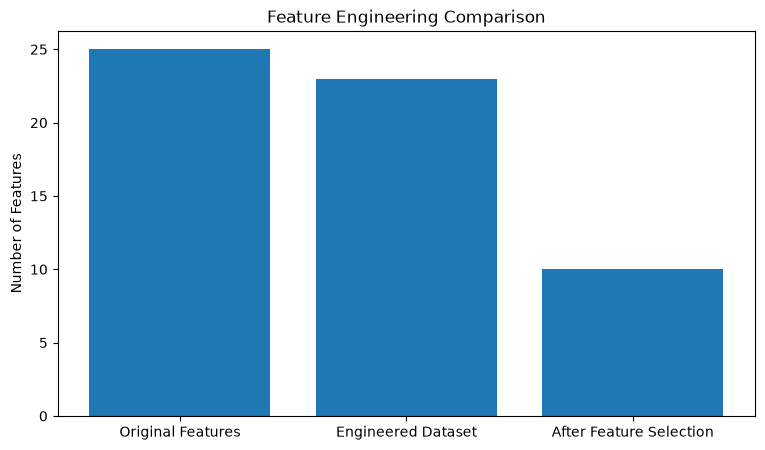

In [18]:
plt.figure(figsize=(9, 5))

labels = [
    "Original Features",
    "Engineered Dataset",
    "After Feature Selection"
]

values = [
    len(df.columns) - 1,
    len(df_clean.columns) - 1,
    len(selected_features)
]

plt.bar(labels, values)

plt.title("Feature Engineering Comparison")
plt.ylabel("Number of Features")
plt.show()

In [19]:
# Save engineered dataset
df_clean.to_csv(
    "banking_feature_engineered.csv",
    index=False
)

# Save selected training features
pd.DataFrame(
    X_train_selected,
    columns=selected_features
).to_csv(
    "banking_selected_features.csv",
    index=False
)

# Save feature explanations
feature_details.to_csv(
    "banking_feature_documentation.csv",
    index=False
)

print("All output files saved successfully!")

All output files saved successfully!


In [20]:
print("=" * 55)
print("NOTEBOOK 16 - MINI CHALLENGE SUMMARY")
print("=" * 55)

print("Dataset Records:", len(df))
print("Original Features:", len(df.columns) - 1)
print("New Features Created: 13")
print("Irrelevant Features Removed:", len(columns_to_remove))
print("Selected Features:", len(selected_features))

print("\nSelected Features:")
for feature in selected_features:
    print("-", feature)

print("\nGenerated Files:")
print("1. banking_feature_engineered.csv")
print("2. banking_selected_features.csv")
print("3. banking_feature_documentation.csv")

print("\nFeature Engineering Mini Challenge Completed!")

NOTEBOOK 16 - MINI CHALLENGE SUMMARY
Dataset Records: 500
Original Features: 25
New Features Created: 13
Irrelevant Features Removed: 2
Selected Features: 10

Selected Features:
- Annual_Income
- Loan_Amount
- Credit_Score
- Missed_Payments
- Monthly_Income
- Loan_to_Income_Ratio
- Payment_Risk
- Credit_Payment_Interaction
- Loan_Credit_Interaction
- Credit_Risk_Category_Excellent

Generated Files:
1. banking_feature_engineered.csv
2. banking_selected_features.csv
3. banking_feature_documentation.csv

Feature Engineering Mini Challenge Completed!
